# FashionVision — Colab Training Notebook

**Before running anything:**
1. Runtime → Change runtime type → GPU (T4)
2. Run cells top to bottom

## Step 1 — Check GPU and TensorFlow version

In [1]:
import tensorflow as tf
import sys

print(f"Python     : {sys.version}")
print(f"TensorFlow : {tf.__version__}")

gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs found : {gpus}")

assert len(gpus) > 0, "No GPU found — go to Runtime > Change runtime type > GPU"

Python     : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
TensorFlow : 2.21.0
GPUs found : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 3 — Get the project

**Option A (recommended): clone from GitHub**  
Replace the URL with your own repo if you've pushed it.

**Option B: unzip from Drive**  
Upload `FashionVision.zip` to Drive first, then use the unzip cell below.

In [3]:
# Option A — GitHub clone (edit the URL to your repo)
!git clone https://github.com/AdityaB197/FashionVision.git /content/FashionVision
%cd /content/FashionVision
!ls

Cloning into '/content/FashionVision'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 25 (delta 0), reused 25 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 10.25 KiB | 5.13 MiB/s, done.
/content/FashionVision
app.py	models	   README.md	     results  src
docs	notebooks  requirements.txt  scripts  tests


In [4]:
# Option B — unzip from Drive (run this instead of Option A if not using GitHub)
# !unzip "/content/drive/MyDrive/FashionVision.zip" -d /content/
# %cd /content/FashionVision
# !ls

## Step 4 — Confirm project structure

In [5]:
!ls -R --ignore='.git'

.:
app.py	models	   README.md	     results  src
docs	notebooks  requirements.txt  scripts  tests

./docs:
ARCHITECTURE.md  REPORT_OUTLINE.md

./models:

./notebooks:
colab_training.ipynb

./results:

./scripts:
evaluate_model.py  train_model.py  verify_project.py

./src:
data.py  inference.py  __init__.py  model.py  reporting.py

./tests:
__init__.py  test_inference.py	test_preprocessing.py


## Step 5 — (Skip pip install)

Colab already has TensorFlow, NumPy, Matplotlib, and scikit-learn.  
Re-installing from requirements.txt can break Colab's TensorFlow build — skip it.

In [6]:
# Quick sanity check — confirm the packages we need are available
import numpy, matplotlib, sklearn
print(f"numpy       {numpy.__version__}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"sklearn     {sklearn.__version__}")
print(f"tensorflow  {tf.__version__}")

numpy       2.1.3
matplotlib  3.10.0
sklearn     1.6.1
tensorflow  2.21.0


## Step 6 — Train

Output goes to Google Drive so it survives after the session ends.

In [7]:
OUTPUT_DIR = "/content/drive/MyDrive/FashionVision_run1"

!python scripts/train_model.py \
    --epochs 20 \
    --batch-size 128 \
    --seed 42 \
    --patience 4 \
    --output-dir "{OUTPUT_DIR}"

GPU(s) detected: ['/physical_device:GPU:0']

Loading data ...
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
  train: (54000, 28, 28, 1)  val: (6000, 28, 28, 1)
W0000 00:00:1792612745.828201    2108 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├──────────────────────

## Step 7 — Evaluate (test set used here for the first and only time)

In [8]:
!python scripts/evaluate_model.py \
    --output-dir "{OUTPUT_DIR}" \
    --model-name fashion_cnn.keras

Loading model from /content/drive/MyDrive/FashionVision_run1/models/fashion_cnn.keras ...
W0000 00:00:1792612810.186259    2943 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Loading test set ...
Predicting on 10000 test images ...

=== Evaluation complete ===
  Test accuracy: 0.9161

Files written:
  /content/drive/MyDrive/FashionVision_run1/results/metrics.json
  /content/drive/MyDrive/FashionVision_run1/results/classification_report.json
  /content/drive/MyDrive/FashionVision_run1/results/confusion_matrix.png
  /content/drive/MyDrive/FashionVision_run1/results/misclassified_examples.png
  /content/drive/MyDrive/FashionVision_run1/results/training_curves.png


## Step 8 — Verify all output files exist in Drive

In [9]:
!ls -lh "{OUTPUT_DIR}/models/"
print()
!ls -lh "{OUTPUT_DIR}/results/"

total 5.3M
-rw------- 1 root root 2.7M Oct 21 19:59 best_model.keras
-rw------- 1 root root  128 Oct 21 20:00 class_names.json
-rw------- 1 root root 2.7M Oct 21 20:00 fashion_cnn.keras
-rw------- 1 root root  524 Oct 21 20:00 metadata.json

total 170K
-rw------- 1 root root 1.7K Oct 21 20:00 classification_report.json
-rw------- 1 root root  64K Oct 21 20:00 confusion_matrix.png
-rw------- 1 root root 2.0K Oct 21 20:00 history.json
-rw------- 1 root root 1.6K Oct 21 20:00 metrics.json
-rw------- 1 root root  57K Oct 21 20:00 misclassified_examples.png
-rw------- 1 root root  43K Oct 21 20:00 training_curves.png


Expected files:

```
models/
  best_model.keras
  fashion_cnn.keras
  class_names.json
  metadata.json

results/
  history.json
  metrics.json
  classification_report.json
  confusion_matrix.png
  misclassified_examples.png
  training_curves.png
```

## Step 9 — Quick results summary

In [10]:
import json
from pathlib import Path

output_dir = Path(OUTPUT_DIR)

with open(output_dir / "results/metrics.json") as f:
    metrics = json.load(f)

with open(output_dir / "models/metadata.json") as f:
    meta = json.load(f)

print(f"Test accuracy  : {metrics['accuracy']:.4f}")
print(f"Macro F1       : {metrics['macro_f1']:.4f}")
print(f"Epochs run     : {meta['epochs_run']} / {meta['epochs_requested']}")
print(f"Best epoch     : {meta['best_epoch']}")
print(f"Training time  : {meta['training_seconds']}s")
print(f"GPU            : {meta['gpu_devices']}")

Test accuracy  : 0.9161
Macro F1       : 0.9158
Epochs run     : 20 / 20
Best epoch     : 16
Training time  : 53.7s
GPU            : ['/physical_device:GPU:0']


## Step 10 — View the plots


--- training_curves.png ---


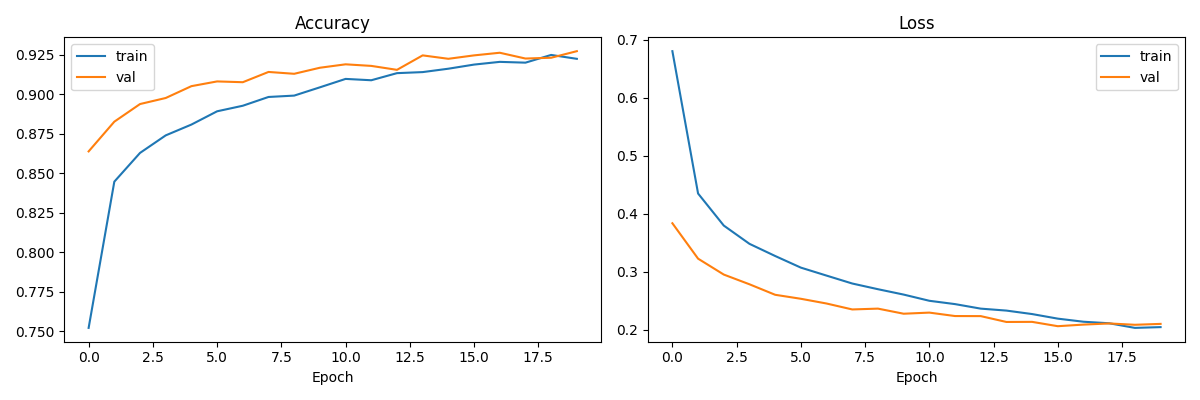


--- confusion_matrix.png ---


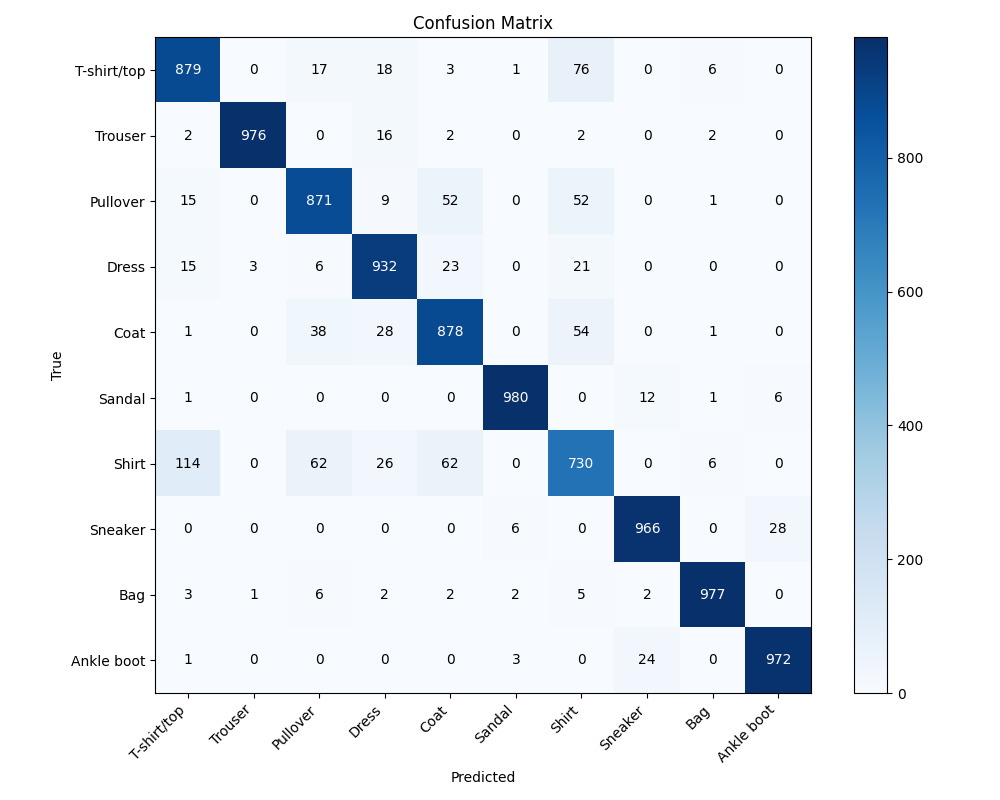


--- misclassified_examples.png ---


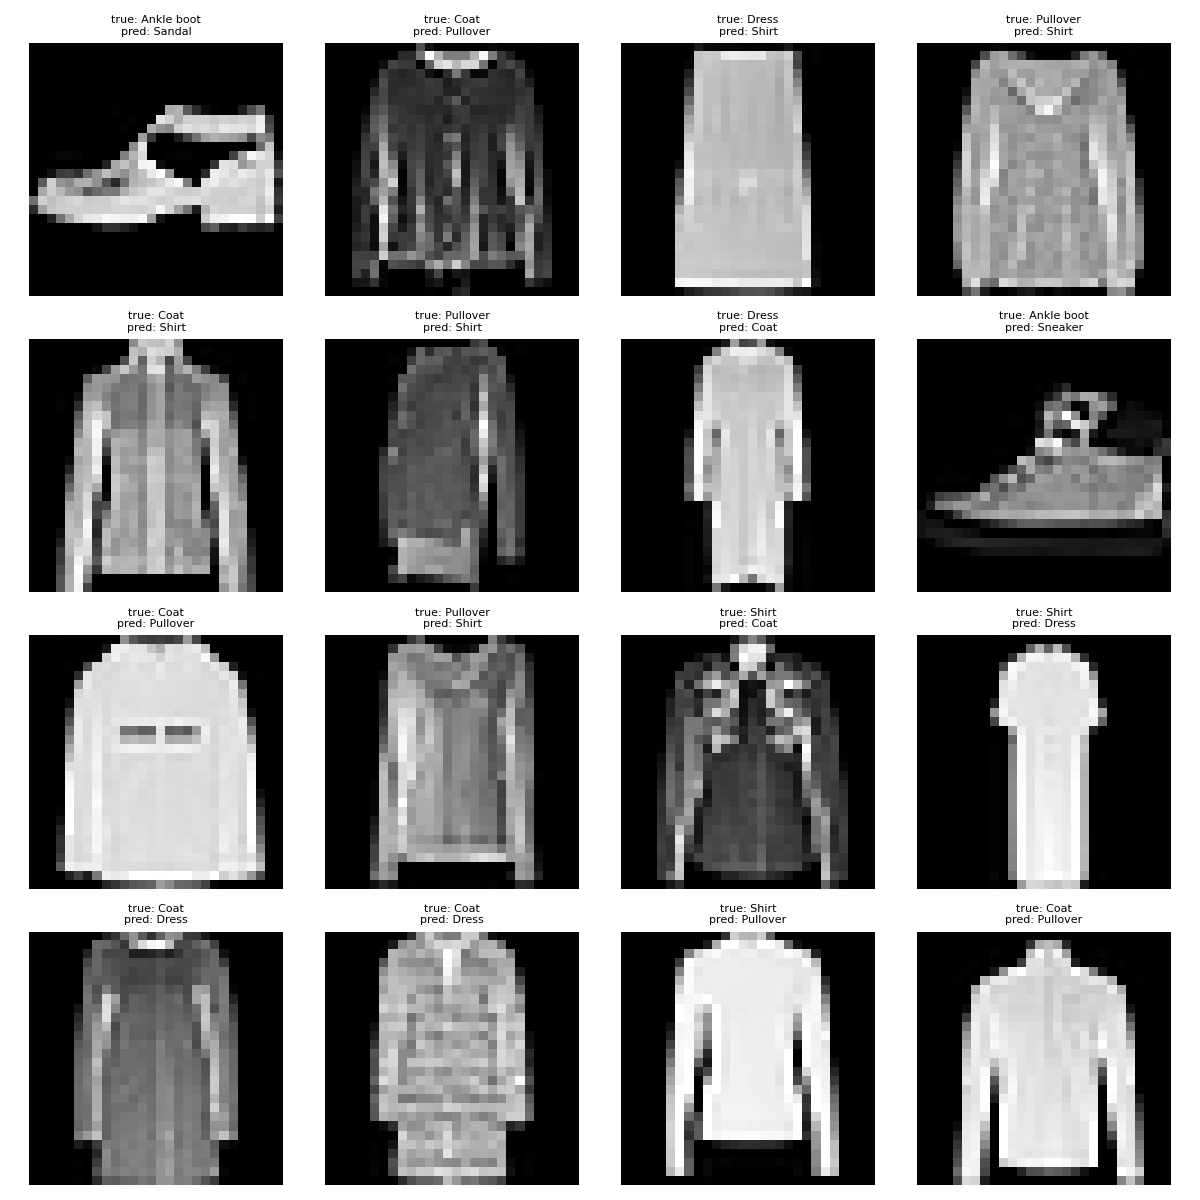

In [11]:
from IPython.display import Image, display

for fname in ["training_curves.png", "confusion_matrix.png", "misclassified_examples.png"]:
    print(f"\n--- {fname} ---")
    display(Image(str(output_dir / "results" / fname)))

---
## Next steps (local)

Download `FashionVision_run1/` from Google Drive and copy:
- `models/` → your local `models/`
- `results/` → your local `results/`

Then run Phase 3 (Streamlit app) locally with:
```bash
streamlit run app.py
```